# Neural Network from Scratch
### Weeks 15–16 Hack-O-Week

This notebook builds a small neural network using NumPy, explains forward and backward propagation, compares SGD and Adam, and saves/loads a trained model with `joblib` and `pickle`.

Dataset: Breast Cancer Wisconsin dataset built into scikit-learn. The example is for learning only and is not a medical diagnostic tool.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import pickle

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

## 1. Load and prepare the dataset

In [2]:
data = load_breast_cancer()
X = data.data.astype(float)
y = data.target.reshape(-1, 1).astype(float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Classes:", data.target_names)

Training shape: (455, 30)
Testing shape: (114, 30)
Classes: ['malignant' 'benign']


## 2. Perceptron and activation functions

A perceptron calculates a weighted sum of inputs plus a bias. An activation function transforms that value. ReLU is commonly used in hidden layers, while sigmoid maps the output to a value between 0 and 1 for binary classification.

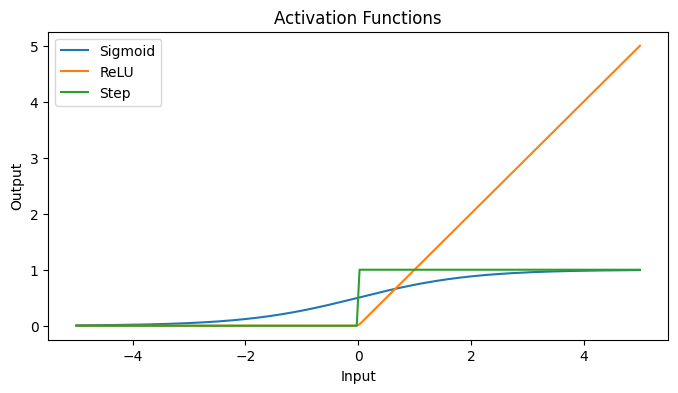

In [3]:
def step(z):
    return (z >= 0).astype(float)

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)

z = np.linspace(-5, 5, 200)
plt.figure(figsize=(8, 4))
plt.plot(z, sigmoid(z), label="Sigmoid")
plt.plot(z, relu(z), label="ReLU")
plt.plot(z, step(z), label="Step")
plt.legend()
plt.title("Activation Functions")
plt.xlabel("Input")
plt.ylabel("Output")
plt.show()

## 3. Neural network from scratch

The network has one hidden layer. Forward propagation produces predictions; binary cross-entropy measures error; backpropagation calculates gradients; the optimizer updates weights.

In [4]:
class NeuralNetwork:
    def __init__(self, input_size, hidden_size=16, learning_rate=0.01, optimizer="sgd", seed=42):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, np.sqrt(2 / input_size), (input_size, hidden_size))
        self.b1 = np.zeros((1, hidden_size))
        self.W2 = rng.normal(0, np.sqrt(1 / hidden_size), (hidden_size, 1))
        self.b2 = np.zeros((1, 1))
        self.lr = learning_rate
        self.optimizer = optimizer.lower()
        self.step_count = 0
        self.params = ["W1", "b1", "W2", "b2"]
        self.m = {p: np.zeros_like(getattr(self, p)) for p in self.params}
        self.v = {p: np.zeros_like(getattr(self, p)) for p in self.params}
        self.loss_history = []

    def forward(self, X):
        self.Z1 = X @ self.W1 + self.b1
        self.A1 = relu(self.Z1)
        self.Z2 = self.A1 @ self.W2 + self.b2
        self.A2 = sigmoid(self.Z2)
        return self.A2

    def loss(self, y, pred):
        pred = np.clip(pred, 1e-8, 1 - 1e-8)
        return -np.mean(y * np.log(pred) + (1 - y) * np.log(1 - pred))

    def backward(self, X, y):
        n = len(X)
        dZ2 = (self.A2 - y) / n
        dW2 = self.A1.T @ dZ2
        db2 = np.sum(dZ2, axis=0, keepdims=True)
        dA1 = dZ2 @ self.W2.T
        dZ1 = dA1 * relu_derivative(self.Z1)
        dW1 = X.T @ dZ1
        db1 = np.sum(dZ1, axis=0, keepdims=True)
        return {"W1": dW1, "b1": db1, "W2": dW2, "b2": db2}

    def update(self, grads):
        self.step_count += 1
        for p in self.params:
            grad = grads[p]
            if self.optimizer == "adam":
                self.m[p] = 0.9 * self.m[p] + 0.1 * grad
                self.v[p] = 0.999 * self.v[p] + 0.001 * (grad ** 2)
                m_hat = self.m[p] / (1 - 0.9 ** self.step_count)
                v_hat = self.v[p] / (1 - 0.999 ** self.step_count)
                value = getattr(self, p) - self.lr * m_hat / (np.sqrt(v_hat) + 1e-8)
            else:
                value = getattr(self, p) - self.lr * grad
            setattr(self, p, value)

    def fit(self, X, y, epochs=300, batch_size=32):
        rng = np.random.default_rng(42)
        for epoch in range(epochs):
            order = rng.permutation(len(X))
            for start in range(0, len(X), batch_size):
                idx = order[start:start + batch_size]
                self.forward(X[idx])
                grads = self.backward(X[idx], y[idx])
                self.update(grads)
            pred = self.forward(X)
            self.loss_history.append(self.loss(y, pred))
        return self

    def predict_proba(self, X):
        return self.forward(X)

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

## 4. Train with SGD

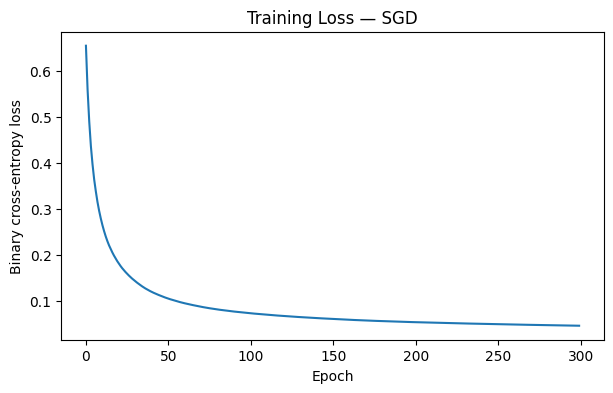

SGD test accuracy: 0.9649


In [5]:
sgd_model = NeuralNetwork(
    input_size=X_train.shape[1],
    hidden_size=16,
    learning_rate=0.01,
    optimizer="sgd"
)
sgd_model.fit(X_train, y_train, epochs=300, batch_size=32)

plt.figure(figsize=(7, 4))
plt.plot(sgd_model.loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Training Loss — SGD")
plt.show()

sgd_predictions = sgd_model.predict(X_test)
print("SGD test accuracy:", round(accuracy_score(y_test, sgd_predictions), 4))

## 5. Train with Adam

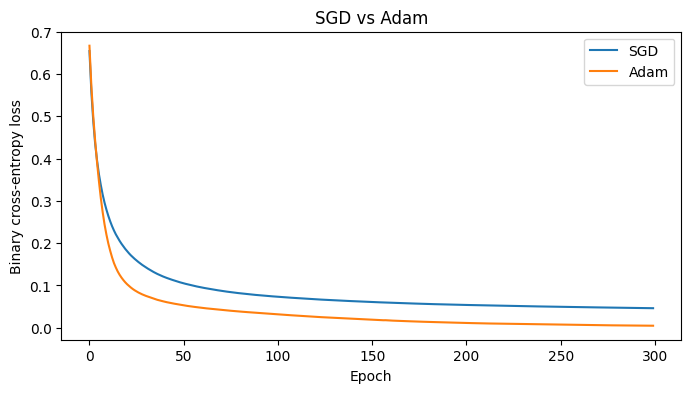

Adam test accuracy: 0.9561


In [6]:
adam_model = NeuralNetwork(
    input_size=X_train.shape[1],
    hidden_size=16,
    learning_rate=0.001,
    optimizer="adam"
)
adam_model.fit(X_train, y_train, epochs=300, batch_size=32)

plt.figure(figsize=(8, 4))
plt.plot(sgd_model.loss_history, label="SGD")
plt.plot(adam_model.loss_history, label="Adam")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("SGD vs Adam")
plt.legend()
plt.show()

adam_predictions = adam_model.predict(X_test)
print("Adam test accuracy:", round(accuracy_score(y_test, adam_predictions), 4))

## 6. Evaluate the selected model

              precision    recall  f1-score   support

   malignant       0.91      0.98      0.94        42
      benign       0.99      0.94      0.96        72

    accuracy                           0.96       114
   macro avg       0.95      0.96      0.95       114
weighted avg       0.96      0.96      0.96       114



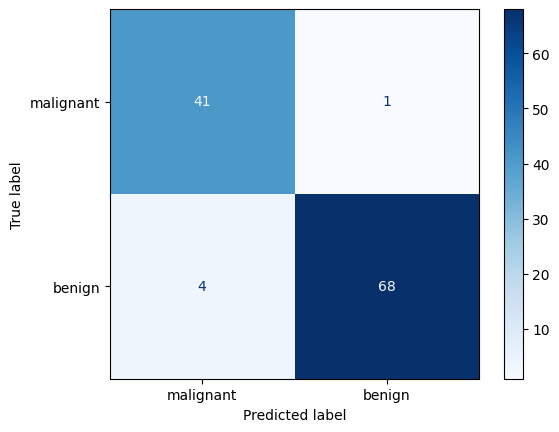

In [7]:
model = adam_model
predictions = model.predict(X_test)

print(classification_report(
    y_test.astype(int), predictions,
    target_names=data.target_names, zero_division=0
))

ConfusionMatrixDisplay.from_predictions(
    y_test.astype(int), predictions,
    display_labels=data.target_names, cmap="Blues"
)
plt.show()

## 7. Forward and backward propagation demonstration

In [8]:
sample_X = X_train[:5]
sample_y = y_train[:5]

sample_predictions = model.forward(sample_X)
sample_loss = model.loss(sample_y, sample_predictions)
gradients = model.backward(sample_X, sample_y)

print("Predictions:\n", sample_predictions.round(3))
print("Loss:", round(float(sample_loss), 4))
print("Gradient shapes:", {key: value.shape for key, value in gradients.items()})

Predictions:
 [[1.]
 [0.]
 [1.]
 [1.]
 [1.]]
Loss: 0.0
Gradient shapes: {'W1': (30, 16), 'b1': (1, 16), 'W2': (16, 1), 'b2': (1, 1)}


## 8. Save and load the model with joblib

Save both the trained network and the scaler, because new input must be scaled the same way as training data.

In [9]:
joblib.dump({"model": model, "scaler": scaler}, "neural_network_model.joblib")
saved_bundle = joblib.load("neural_network_model.joblib")

loaded_model = saved_bundle["model"]
loaded_scaler = saved_bundle["scaler"]

loaded_predictions = loaded_model.predict(loaded_scaler.transform(data.data[:10]))
print("Loaded model predictions:", loaded_predictions.ravel())

Loaded model predictions: [0 0 0 0 0 0 0 0 0 0]


## 9. Save and load with pickle

In [10]:
with open("neural_network_model.pkl", "wb") as file:
    pickle.dump({"model": model, "scaler": scaler}, file)

with open("neural_network_model.pkl", "rb") as file:
    loaded_bundle_pickle = pickle.load(file)

pickle_model = loaded_bundle_pickle["model"]
pickle_scaler = loaded_bundle_pickle["scaler"]

print("Pickle model predictions:", pickle_model.predict(pickle_scaler.transform(data.data[:10])).ravel())

Pickle model predictions: [0 0 0 0 0 0 0 0 0 0]


## 10. Predict one example

In [11]:
example = data.data[[0]]
example_scaled = loaded_scaler.transform(example)
probability = float(loaded_model.predict_proba(example_scaled)[0, 0])
predicted_class = int(probability >= 0.5)

print("Predicted class:", data.target_names[predicted_class])
print("Predicted probability for class 1:", round(probability, 4))

Predicted class: malignant
Predicted probability for class 1: 0.0


## Conclusion
This notebook implements a perceptron-style neural network with a ReLU hidden layer and sigmoid output using NumPy. It demonstrates forward propagation, binary cross-entropy loss, backpropagation, SGD and Adam updates, evaluation, and saving/loading the model with joblib and pickle. The dataset is for educational classification only; predictions must not be used for medical decisions.